# Reconstruction Methods Compared

This notebook compares the reconstruction methods in ETSpy on a simulated object whose true
density is known, so that every result can be scored. You will learn:

* What each method does, and its main parameters: filtered backprojection (`"FBP"`), `"SIRT"`,
  `"SART"`, `"DART"`, and the total variation (TV) methods `"FISTA"` and `"ASD-POCS"`
* How noise changes the picture, and why the number of SIRT iterations acts as a smoothing
  parameter
* How the TV weight trades noise against the size of thin features
* What happens with fewer tilts, and with a limited tilt range (the missing wedge)
* How to run the reconstructions on a GPU or on several CPU cores

The numbers quoted in the text are from one run on the CPU; noise is random, so a new run differs
slightly.

## Imports

In [1]:
%matplotlib inline

import time

import matplotlib.pyplot as plt
import numpy as np
import hyperspy.api as hs
from scipy import ndimage

import etspy.api as tomo
from etspy import simulation as sim

tomo.set_log_level("WARNING")
rng = np.random.default_rng(0)

## A Test Object with Known Features

The object is the cross-section of a needle-shaped specimen, 192 x 192 pixels:

* a round body of density 1
* a dense block of density 2
* three thin bars of density 2, **2, 4 and 8 pixels wide**, to test how well each method keeps
  the size of small features
* a small round particle of density 2

The edges are slightly blurred, as in a real image. The same slice is repeated four times along
the tilt axis, so that the 3D TV methods have a volume to work on.

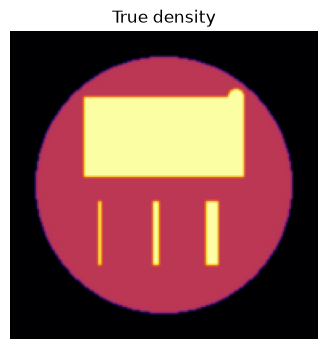

In [2]:
n = 192
yy, xx = np.mgrid[:n, :n] - (n - 1) / 2
obj = np.zeros((n, n), np.float32)
obj[xx**2 + yy**2 < 80**2] = 1.0                       # body
obj[(abs(yy + 30) < 25) & (abs(xx) < 50)] = 2.0         # dense block
bar_centres, bar_widths = (-40, -5, 30), (2, 4, 8)
for c, w in zip(bar_centres, bar_widths):               # thin bars
    obj[(abs(yy - 30) < 20) & (abs(xx - c) < w / 2)] = 2.0
obj[(xx - 45) ** 2 + (yy + 55) ** 2 < 5**2] = 2.0       # particle
obj = ndimage.gaussian_filter(obj, 0.7)
model = np.repeat(obj[np.newaxis], 4, axis=0)           # (slices along the tilt axis, y, z)

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(obj, cmap="inferno")
ax.set_title("True density")
ax.axis("off");

### Tilt Series and Scores

`create_model_tilt_series` projects the model at the tilts given. Shot noise is added by drawing
Poisson counts: `dose` is the number of counts per unit of projected density, so a higher dose
means less noise.

Two scores are used:

* the **error**: the difference from the true density, relative to the true density (0 is
  perfect)
* the **widths of the three bars**, measured in the same way on the truth and on each
  reconstruction: the full width at half of the bar's height above its surroundings, along a
  profile averaged over the middle of the bars

In [3]:
def make_series(step=2.0, dose=None, tilt_range=180):
    """Tilt series of the model at uniform steps, with Poisson noise if dose is given."""
    if tilt_range >= 180:
        tilts = np.arange(-90, 90, step)                # 180 deg: -90 and +90 are the same
    else:
        tilts = np.arange(-tilt_range / 2, tilt_range / 2 + step / 2, step)
    series = sim.create_model_tilt_series(model, angles=tilts)
    if dose is not None:
        series.data = rng.poisson(series.data * dose).astype(np.float32) / dose
    return series


def error(rec):
    """Difference from the true density, relative to the true density."""
    return np.linalg.norm(rec.data[1] - obj) / np.linalg.norm(obj)


rows = slice(int(n / 2 + 18), int(n / 2 + 42))


def widths(img):
    """Full width at half height of the three bars (pixels)."""
    profile = img[rows].mean(axis=0)
    out = []
    for c in bar_centres:
        i0 = int(round(c + (n - 1) / 2))
        seg = profile[i0 - 12 : i0 + 13]
        base = np.median(np.r_[seg[:4], seg[-4:]])
        half = (base + seg[10:15].max()) / 2
        above = np.where(seg > half)[0]
        a, b = above[0], above[-1]
        if a == 0 or b == len(seg) - 1:                 # no clear bar: no width
            out.append(np.nan)
            continue
        left = a - 1 + (half - seg[a - 1]) / (seg[a] - seg[a - 1])
        right = b + (seg[b] - half) / (seg[b] - seg[b + 1])
        out.append(right - left)
    return np.array(out)


true_widths = widths(obj)
print("true bar widths (px):", np.round(true_widths, 2))

true bar widths (px): [2.38 4.02 8.  ]


## The Methods

| Method | Call | Main parameters | Notes |
|---|---|---|---|
| Filtered backprojection | `reconstruct("FBP")` | `sino_filter` | Fast and linear; streaks and noise with few tilts |
| SIRT | `reconstruct("SIRT", iterations=...)` | `iterations`, `constrain`, `thresh` | All projections at once; slow to converge, so stopping early smooths |
| SART | `reconstruct("SART", iterations=...)` | `iterations` (passes through the data) | One projection at a time; converges in a few passes |
| DART | `reconstruct("DART", gray_levels=[...])` | `gray_levels`, `dart_iterations`, `p` | Assumes a few known densities; segments as it goes |
| FISTA-TV | `reconstruct_tv("FISTA", tv_weight=...)` | `tv_weight`, `iterations`, `tv_dims` | Penalizes the total variation; uniform regions, sharp edges |
| ASD-POCS | `reconstruct_tv("ASD-POCS")` | `iterations`, `eps`, `alpha` | Alternates SART with TV steps; for few tilts with little noise |

`constrain=True` keeps the iterative results non-negative, and `thresh` sets the lower limit.
The helper below runs a set of methods on a series and collects the scores and run times.

In [4]:
quiet = dict(show_progressbar=False)
methods = {
    "FBP": lambda s: s.reconstruct("FBP", **quiet),
    "SIRT (50)": lambda s: s.reconstruct("SIRT", iterations=50, constrain=True, **quiet),
    "SIRT (200)": lambda s: s.reconstruct("SIRT", iterations=200, constrain=True, **quiet),
    "SART (5)": lambda s: s.reconstruct("SART", iterations=5, constrain=True, **quiet),
    "DART": lambda s: s.reconstruct("DART", iterations=5, gray_levels=[0, 1, 2], **quiet),
    "FISTA-TV": lambda s: s.reconstruct_tv("FISTA", iterations=50, tv_weight=0.1, **quiet),
    "ASD-POCS": lambda s: s.reconstruct_tv("ASD-POCS", iterations=50, **quiet),
}


def run_all(series, which=methods):
    results = {}
    for name, method in which.items():
        t0 = time.perf_counter()
        rec = method(series)
        results[name] = dict(rec=rec, error=error(rec), widths=widths(rec.data[1]),
                             seconds=time.perf_counter() - t0)
    return results


def show(results, title):
    names = list(results)
    hs.plot.plot_images(
        [hs.signals.Signal2D(obj)] + [hs.signals.Signal2D(results[k]["rec"].data[1]) for k in names],
        cmap="inferno", vmin=0, vmax=2.3, per_row=4, axes_decor="off", colorbar=None,
        label=["Truth"] + names,
    )
    plt.gcf().set_size_inches(12, 7.5)
    plt.gcf().suptitle(title)
    plt.tight_layout()
    print(f"{'method':12s} {'error':>6s}   bar widths (true {np.round(true_widths, 1)})   time (s)")
    for k in names:
        r = results[k]
        print(f"{k:12s} {r['error']:6.3f}   {np.array2string(r['widths'], precision=1):>28s}"
              f"   {r['seconds']:6.1f}")

## Without Noise

With 90 projections over 180\u00b0 (2\u00b0 steps) and no noise, every method gives a
recognizable object:

* SIRT keeps improving as it converges (200 iterations are better than 50), and FISTA-TV is as
  good; both keep the bar widths within about 0.5 pixel
* FBP and SART (5 passes) are close behind
* DART is accurate in the uniform regions but loses the narrowest bar, which is too thin for its
  segmentation
* ASD-POCS with its default settings smooths too much for this object: the 2 and 4 pixel bars come
  out much too wide. Its parameters (`alpha`, `eps`) suit fewer tilts and simpler objects

method        error   bar widths (true [2.4 4.  8. ])   time (s)
FBP           0.092                  [2.6 4.1 8. ]      0.1
SIRT (50)     0.059                  [3.7 4.8 8.3]      5.3
SIRT (200)    0.018                  [2.8 4.1 8. ]     20.4
SART (5)      0.076                  [2.5 3.9 7.9]      1.0
DART          0.088                  [8.9 4.8 8.3]      5.1
FISTA-TV      0.014                  [3.1 4.3 8. ]     17.1
ASD-POCS      0.124                  [6.8 7.2 9.1]     16.4


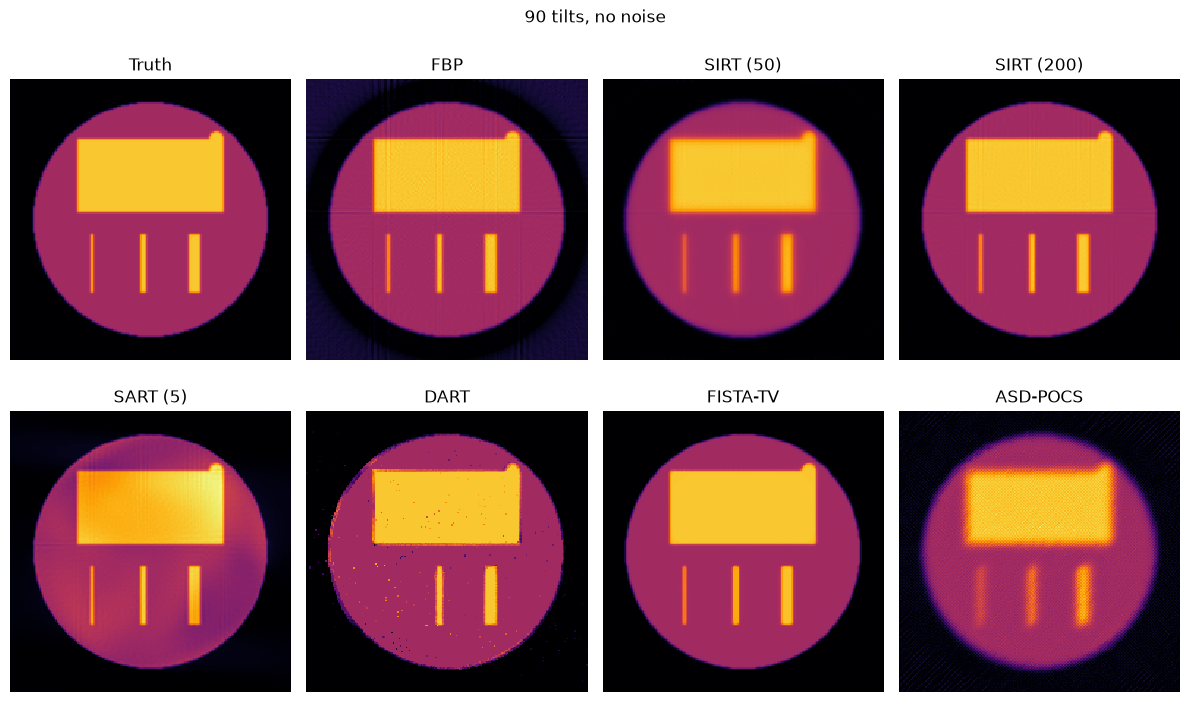

In [5]:
clean = make_series(step=2)
res_clean = run_all(clean)
show(res_clean, "90 tilts, no noise")

## With Noise

Real data are noisy. At a dose of 5 counts per unit of projected density, the ranking changes:

* FBP reproduces the noise in full
* **SIRT stopped at 50 iterations beats SIRT at 200**: SIRT fits the large-scale structure first
  and the noise last, so running it longer fits more noise (semi-convergence)
* SART, which converges much faster, behaves like a long SIRT run here
* the TV methods suppress the noise best

But look at the narrowest bar: every method that suppresses noise also widens it (SIRT at 50
iterations and both TV methods), while the noisier long SIRT run keeps its width best. Noise
suppression and resolution trade against each other, so a method chosen for the lowest overall
error is not necessarily the right one for measuring small features.

method        error   bar widths (true [2.4 4.  8. ])   time (s)
FBP           0.331                  [2.9 4.4 7.6]      0.1
SIRT (50)     0.100                  [3.7 5.  7.9]      5.2
SIRT (200)    0.202                  [2.9 4.3 7.6]     20.5
SART (5)      0.306                  [2.7 4.1 7.6]      0.8
DART          0.240               [14.8  3.8  4.8]      5.0
FISTA-TV      0.057                  [3.4 4.2 7.7]     17.1
ASD-POCS      0.049                  [4.6 4.7 8. ]     16.0


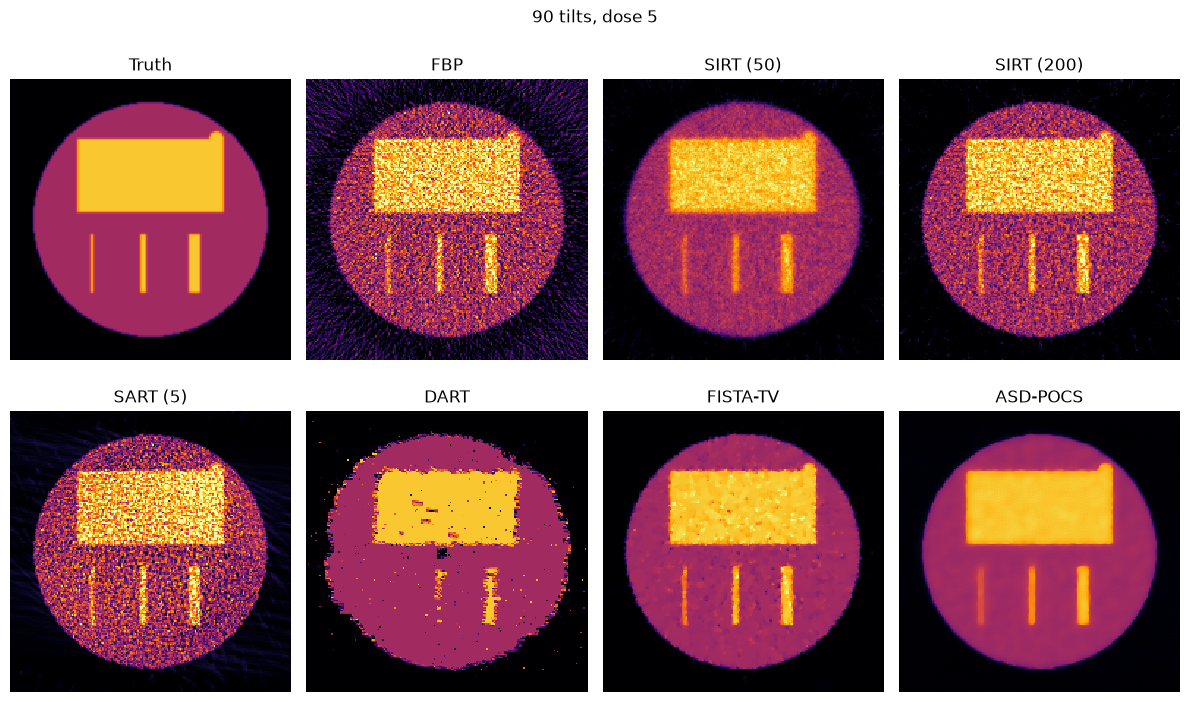

In [6]:
noisy = make_series(step=2, dose=5)
res_noisy = run_all(noisy)
show(res_noisy, "90 tilts, dose 5")

### Choosing the Number of SIRT Iterations

`recon_error` runs SIRT on one slice and keeps the reconstruction and the *data* error (the
difference between the reprojected reconstruction and the data) at every iteration. Here we can
also compute the *true* error at every iteration. The data error keeps falling, while the true
error reaches a minimum and then rises as the noise is fitted. On real data only the data error is
available; a good rule is to stop where its fall slows down.

  0%|          | 0/300 [00:00<?, ?it/s]

  1%|          | 2/300 [00:00<00:20, 14.84it/s]

  1%|▏         | 4/300 [00:00<00:21, 13.89it/s]

  2%|▏         | 6/300 [00:00<00:19, 14.81it/s]

  3%|▎         | 8/300 [00:00<00:21, 13.90it/s]

  3%|▎         | 10/300 [00:00<00:19, 14.81it/s]

... (142 outputs left out)

 99%|█████████▊| 296/300 [00:21<00:00, 13.40it/s]

 99%|█████████▉| 298/300 [00:21<00:00, 13.76it/s]

100%|██████████| 300/300 [00:21<00:00, 13.69it/s]

100%|██████████| 300/300 [00:21<00:00, 13.77it/s]

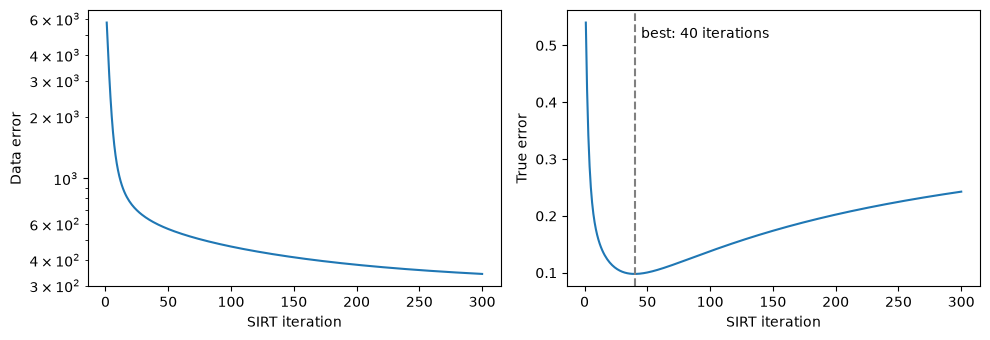

In [7]:
steps, data_error = noisy.recon_error(1, iterations=300)
true_error = [np.linalg.norm(s - obj) / np.linalg.norm(obj) for s in steps.data]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(np.arange(1, 301), data_error.data)
ax[0].set(xlabel="SIRT iteration", ylabel="Data error", yscale="log")
ax[1].plot(np.arange(1, 301), true_error)
best = int(np.argmin(true_error)) + 1
ax[1].axvline(best, ls="--", color="gray")
ax[1].set(xlabel="SIRT iteration", ylabel="True error")
ax[1].text(best + 5, max(true_error) * 0.95, f"best: {best} iterations")
fig.tight_layout()

### The TV Weight

The FISTA-TV weight sets how strongly variation is penalized. Too small and the noise remains;
too large and the image becomes patchy, and thin features lose contrast and grow wider, because
each edge of a feature costs a penalty. Here the lowest overall error is at a weight of 0.3, where
the 2 pixel bar is already almost twice too wide. If feature sizes are what you measure, choose the
weight for them, and check them against SIRT or against simulations like this one.

tv_weight  error   bar widths (true [2.4 4.  8. ])
     0.01  0.258                  [2.7 4.1 7.6]
     0.03  0.188                  [2.9 4.1 7.7]
     0.10  0.057                  [3.4 4.2 7.7]
     0.30  0.036                  [4.3 4.7 8. ]
     1.00  0.057                  [7.5 6.3 8.4]


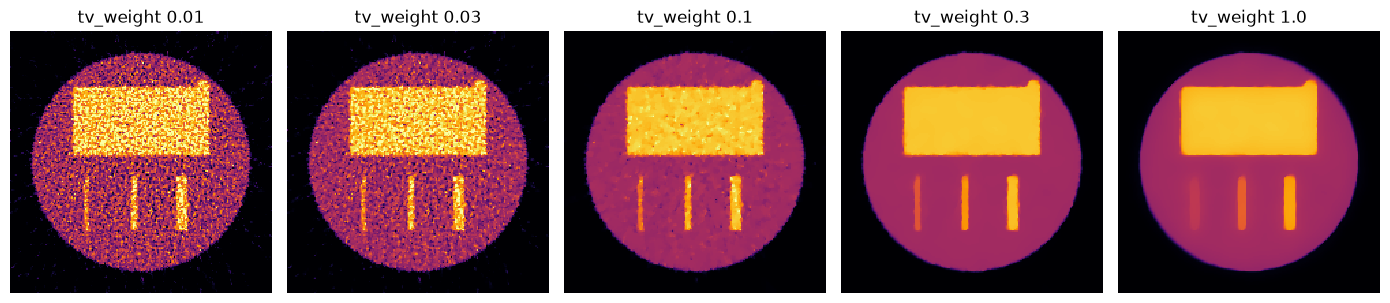

In [8]:
weights = [0.01, 0.03, 0.1, 0.3, 1.0]
tv_runs = {w: noisy.reconstruct_tv("FISTA", iterations=50, tv_weight=w, show_progressbar=False)
           for w in weights}

hs.plot.plot_images(
    [hs.signals.Signal2D(tv_runs[w].data[1]) for w in weights],
    cmap="inferno", vmin=0, vmax=2.3, per_row=5, axes_decor="off", colorbar=None,
    label=[f"tv_weight {w}" for w in weights],
)
plt.gcf().set_size_inches(14, 3.4)
plt.tight_layout()

print(f"{'tv_weight':>9s} {'error':>6s}   bar widths (true {np.round(true_widths, 1)})")
for w in weights:
    print(f"{w:9.2f} {error(tv_runs[w]):6.3f}   "
          f"{np.array2string(widths(tv_runs[w].data[1]), precision=1):>28s}")

## Fewer Tilts

Fewer projections leave gaps in the data between the measured directions, which show as streaks
radiating from dense features. Here the dose per projection is kept fixed, so fewer tilts also
means less total dose. FBP degrades fastest and SIRT steadily, while FISTA-TV hardly changes down
to 18 tilts: this object is made of uniform regions with sharp edges, exactly what TV assumes. Real
specimens are rarely that simple, so the advantage is usually smaller.

FBP        [0.326, 0.463, 0.584, 0.75]
SIRT (50)  [0.1, 0.12, 0.131, 0.141]
FISTA-TV   [0.057, 0.048, 0.047, 0.053]


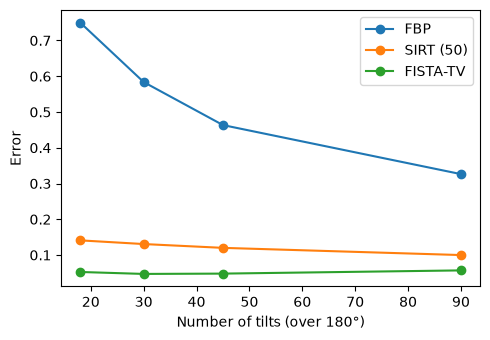

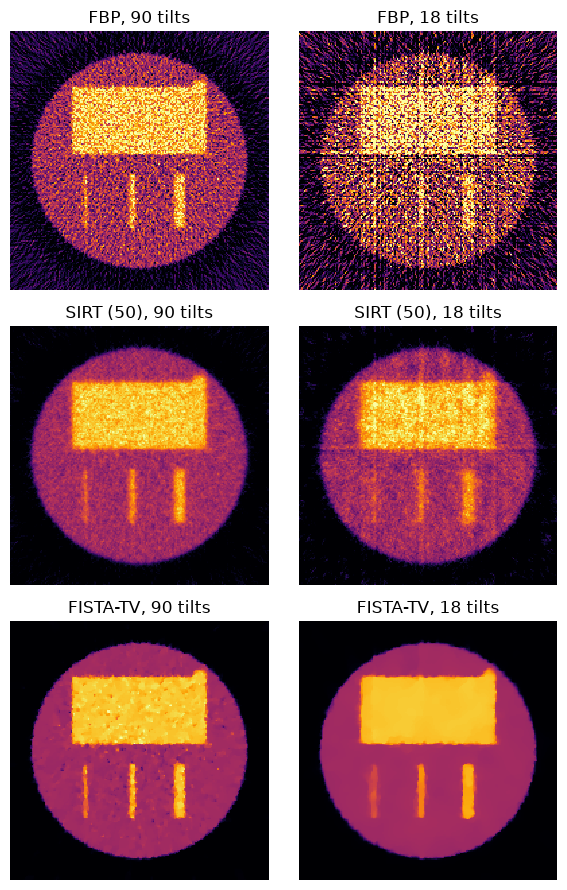

In [9]:
few = {"FBP": methods["FBP"], "SIRT (50)": methods["SIRT (50)"], "FISTA-TV": methods["FISTA-TV"]}
steps_deg = [2, 4, 6, 10]
sweep = {s: run_all(make_series(step=s, dose=5), few) for s in steps_deg}

fig, ax = plt.subplots(figsize=(5, 3.5))
for name in few:
    ax.plot([180 // s for s in steps_deg], [sweep[s][name]["error"] for s in steps_deg],
            "o-", label=name)
ax.set(xlabel="Number of tilts (over 180\u00b0)", ylabel="Error")
for name in few:
    print(f"{name:10s}", [round(float(sweep[s][name]["error"]), 3) for s in steps_deg])
ax.legend()
fig.tight_layout()

hs.plot.plot_images(
    [hs.signals.Signal2D(sweep[s][name]["rec"].data[1]) for name in few for s in (2, 10)],
    cmap="inferno", vmin=0, vmax=2.3, per_row=2, axes_decor="off", colorbar=None,
    label=[f"{name}, {180 // s} tilts" for name in few for s in (2, 10)],
)
plt.gcf().set_size_inches(6, 9)
plt.tight_layout()

## Limited Tilt Range: the Missing Wedge

Most specimens can only be tilted to about \u00b170\u00b0. The directions that are never measured
form a *missing wedge* in Fourier space: features elongate along the beam direction at 0\u00b0
(vertical in these images), and edges parallel to it fade. A needle-shaped specimen rotated through
180\u00b0 avoids this. TV methods partly fill in the missing information, by assuming uniform
regions with sharp edges.

method        error   bar widths (true [2.4 4.  8. ])   time (s)
SIRT (50)     0.172                  [3.9 4.9 8. ]      3.9
FISTA-TV      0.116                  [3.5 4.3 8. ]     15.2
ASD-POCS      0.120                  [4.6 4.9 8.2]     12.9


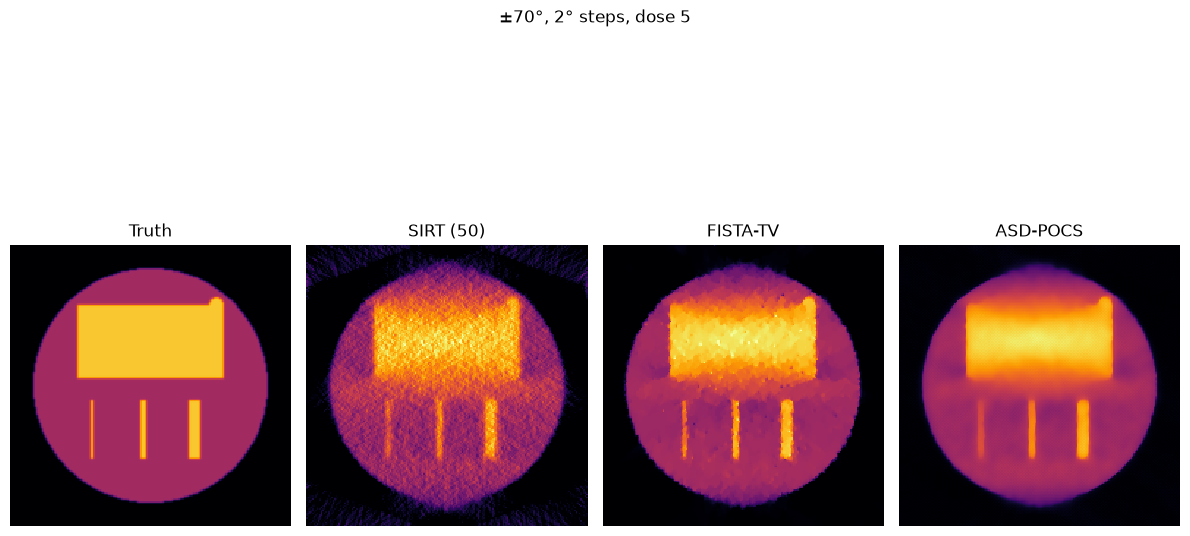

In [10]:
wedge = make_series(step=2, dose=5, tilt_range=140)
res_wedge = run_all(wedge, {"SIRT (50)": methods["SIRT (50)"], "FISTA-TV": methods["FISTA-TV"],
                            "ASD-POCS": methods["ASD-POCS"]})
show(res_wedge, "\u00b170\u00b0, 2\u00b0 steps, dose 5")

## Speed: GPU and CPU

* All reconstruction methods take `cuda=True` to run on a CUDA GPU; the default (`cuda=None`)
  uses the GPU when one is available
* On the CPU, slices are reconstructed in parallel; `ncores` sets the number of processes
  (default: most of the cores)
* `thickness` sets the size of the reconstruction along the beam direction (default: the width of
  the projections), which saves time and memory for thin, flat specimens
* The TV methods with `tv_dims=3` regularize the whole volume at once; `tv_dims=2` treats each
  slice independently, which is faster on the CPU

The run times measured above (on this machine's CPU) were:

In [11]:
for name, r in res_noisy.items():
    print(f"{name:12s} {r['seconds']:6.1f} s")

FBP             0.1 s
SIRT (50)       5.2 s
SIRT (200)     20.5 s
SART (5)        0.8 s
DART            5.0 s
FISTA-TV       17.1 s
ASD-POCS       16.0 s


## Summary

| Situation | Suggested method |
|---|---|
| Quick look, alignment checks | FBP, or `test_align` |
| General use | SIRT, stopped early (choose with `recon_error`) |
| Noisy data, visualization and segmentation | FISTA-TV (tune `tv_weight`) |
| Measuring small features | SIRT, with the size bias checked by simulation: every method that smooths widens features near the resolution limit |
| Few tilts or a missing wedge, little noise | ASD-POCS or FISTA-TV |
| An object made of a few known densities | DART |

Whatever the method, a reconstruction is only as good as the alignment of the data (see the
[alignment notebook](alignment_in_depth.ipynb)), and the choice of tilts matters as much as the
method (see the [tilt scheme notebook](tilt_scheme_design.ipynb)).